In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the Mall Customers dataset

df = pd.read_csv("Mall_Customers.csv")

# Display the first 5 rows
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
# Check the number of rows and columns

print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (200, 5)
Number of Rows: 200
Number of Columns: 5


In [4]:
# Display dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
# Check for missing values

print(df.isnull().sum())

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [6]:
# Generate descriptive statistics

df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


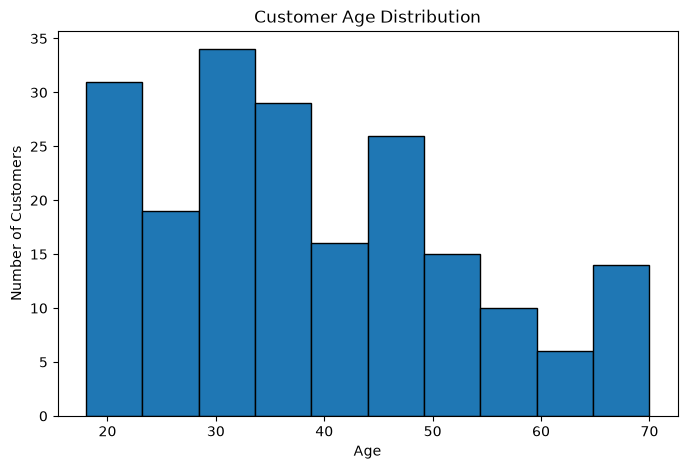

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(df['Age'], bins=10, edgecolor='black')

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

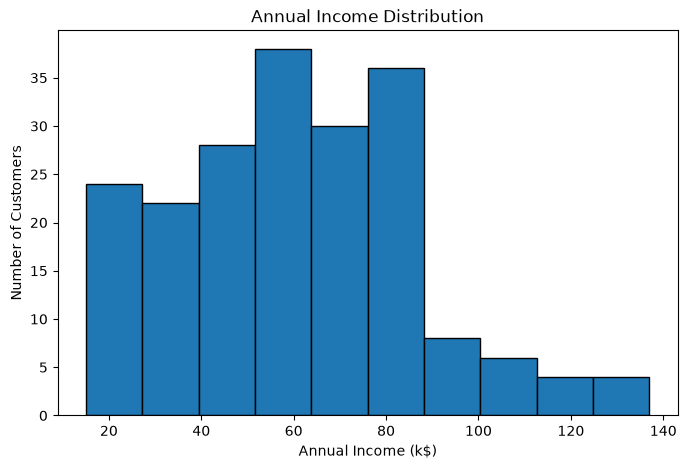

In [8]:
# Visualize annual income distribution

plt.figure(figsize=(8, 5))

plt.hist(df['Annual Income (k$)'], bins=10, edgecolor='black')

plt.title('Annual Income Distribution')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Number of Customers')

plt.show()

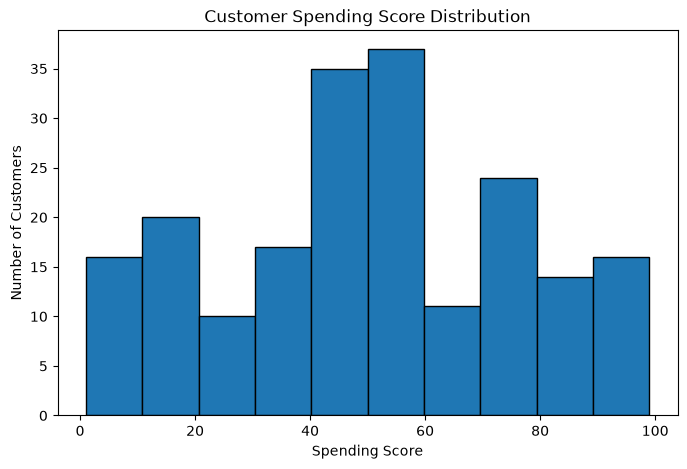

In [9]:
# Visualize spending score distribution

plt.figure(figsize=(8, 5))

plt.hist(df['Spending Score (1-100)'], bins=10, edgecolor='black')

plt.title('Customer Spending Score Distribution')
plt.xlabel('Spending Score')
plt.ylabel('Number of Customers')

plt.show()

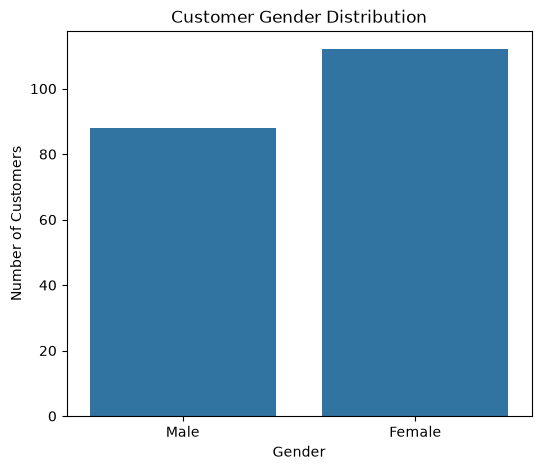

In [10]:
# Visualize gender distribution

plt.figure(figsize=(6, 5))

sns.countplot(data=df, x='Genre')

plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

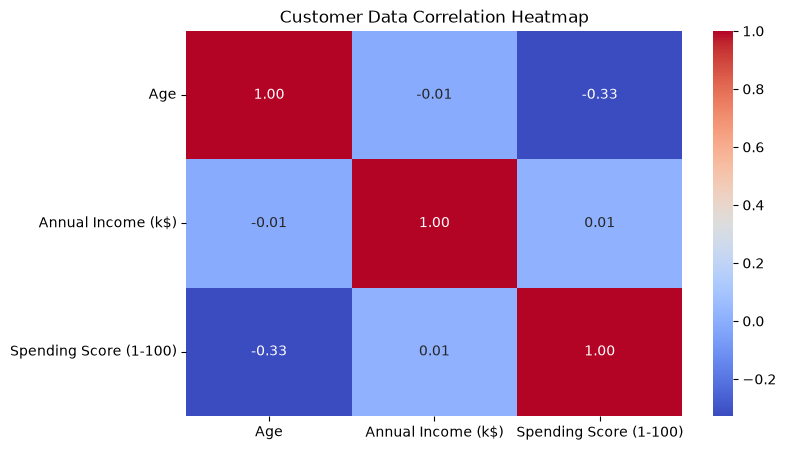

In [11]:
# Correlation analysis

correlation = df[['Age', 'Annual Income (k$)',
                  'Spending Score (1-100)']].corr()

plt.figure(figsize=(8, 5))

sns.heatmap(correlation, annot=True, cmap='coolwarm',
            fmt='.2f')

plt.title('Customer Data Correlation Heatmap')

plt.show()

In [12]:
# Encode categorical data

df['Gender_Encoded'] = df['Genre'].map({
    'Male': 1,
    'Female': 0
})

# Display the result

df[['Genre', 'Gender_Encoded']].head(10)

,Genre,Gender_Encoded
0,Male,1
1,Male,1
2,Female,0
3,Female,0
4,Female,0
5,Female,0
6,Female,0
7,Female,0
8,Male,1
9,Female,0


In [13]:
# Check for duplicate records

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [14]:
# Remove unnecessary CustomerID column

ml_data = df.drop(columns=['CustomerID', 'Genre'])

# Display the prepared dataset

ml_data.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded
0,19,15,39,1
1,21,15,81,1
2,20,16,6,0
3,23,16,77,0
4,31,17,40,0


In [15]:
# Check prepared dataset dimensions

print("Prepared Dataset Shape:", ml_data.shape)
print("\nColumn Names:")
print(ml_data.columns.tolist())

print("\nData Types:")
print(ml_data.dtypes)

Prepared Dataset Shape: (200, 4)

Column Names:
['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Gender_Encoded']

Data Types:
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
Gender_Encoded            int64
dtype: object


In [16]:
# Feature scaling using StandardScaler

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Scale continuous numerical features
scaled_columns = ['Age', 'Annual Income (k$)',
                  'Spending Score (1-100)']

ml_data[scaled_columns] = scaler.fit_transform(
    ml_data[scaled_columns]
)

# Display the scaled dataset
ml_data.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded
0,-1.424569,-1.738999,-0.434801,1
1,-1.281035,-1.738999,1.195704,1
2,-1.352802,-1.700830,-1.715913,0
3,-1.137502,-1.700830,1.040418,0
4,-0.563369,-1.662660,-0.395980,0


In [17]:
# Verify feature scaling

print("Mean of scaled features:")
print(ml_data[scaled_columns].mean())

print("\nStandard deviation of scaled features:")
print(ml_data[scaled_columns].std())

Mean of scaled features:
Age                      -1.021405e-16
Annual Income (k$)       -2.131628e-16
Spending Score (1-100)   -1.465494e-16
dtype: float64

Standard deviation of scaled features:
Age                       1.002509
Annual Income (k$)        1.002509
Spending Score (1-100)    1.002509
dtype: float64


In [18]:
# Save the preprocessed dataset

ml_data.to_csv("Mall_Customers_Preprocessed.csv", index=False)

print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


In [19]:
# Load the saved preprocessed dataset

final_df = pd.read_csv("Mall_Customers_Preprocessed.csv")

print("Final Dataset Shape:", final_df.shape)

print("\nFirst 5 Records:")
display(final_df.head())

print("\nMissing Values:")
print(final_df.isnull().sum())

Final Dataset Shape: (200, 4)

First 5 Records:


,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded
0,-1.424569,-1.738999,-0.434801,1
1,-1.281035,-1.738999,1.195704,1
2,-1.352802,-1.700830,-1.715913,0
3,-1.137502,-1.700830,1.040418,0
4,-0.563369,-1.662660,-0.395980,0



Missing Values:
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
Gender_Encoded            0
dtype: int64


## Conclusion

The Mall Customer Segmentation dataset was successfully explored and preprocessed using Python.

The dataset contains 200 records and 5 original columns. Data exploration was performed using descriptive statistics, histograms, and a correlation heatmap.

The dataset was checked for missing values and duplicate records. No missing values or duplicate records were found.

The categorical feature (Genre) was converted into numerical values using label encoding. The CustomerID and original Genre columns were removed from the modeling dataset. StandardScaler was applied to scale the numerical features.

Finally, the preprocessed dataset containing 200 records and 4 columns was saved as `Mall_Customers_Preprocessed.csv`.

**Result:** Dataset exploration and preprocessing were completed successfully.